 -4 -3 -3 -2 -2 -2 -1 -1 -1 -1 1 1 1 1 2 2 2 3 3 4
 0.5


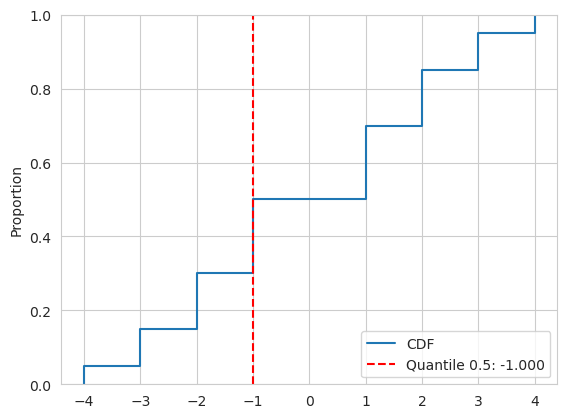

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 


sns.set_style("whitegrid")
data = [*map(float, input().split())]
p = float(input())
sns.ecdfplot(data=data, label='CDF')
q = np.quantile(data, p, method='inverted_cdf')
plt.axvline(q, color='red', linestyle='--', label=f'Quantile {p}: {q:.3f}')
plt.grid(True)
plt.legend()
plt.show()

## Замечание

**Как работает `np.quantile(...)` при выборе метода `inverted_cdf`?**

Метод `inverted_cdf` вычисляет выборочный квантиль с помощью обратной эмпирической функции распределения.

Общая формула вычисления квантиля:

$$
Q(\alpha) = (1-d)\cdot x[j] + d\cdot x[j+1],
$$

где:
- $x$ — отсортированная выборка;
- $n$ — объём выборки;
- $\alpha$ — уровень квантиля.

Для метода `inverted_cdf` индекс $j$ и коэффициент $d$ определяются следующим образом:

$$
j = \lfloor \alpha n - 1 \rfloor,
$$

$$
d = \operatorname{int}(\alpha n - 1 - j > 0).
$$

Поскольку $d \in \{0,1\}$, результат всегда совпадает с одним из элементов выборки.

**Математическое определение метода:**

$$
Q(\alpha) = \inf\{x : F_n(x) \geq \alpha\},
$$

где $F_n(x)$ — эмпирическая функция распределения.

Таким образом, **`inverted_cdf` не является сглаживающим методом**, поскольку не выполняет интерполяцию между соседними элементами выборки.